In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Considere el proyecto cuyo cuadro de prelaciones y duraciones (en semanas) se adjunta.

In [3]:
pregunta_1 = "1. Calcule el calendario del proyecto con las holguras total, libre e independiente.  "
pregunta_2 = "2. D y G son consecutivas y tienen la misma holgura total. El responsable de D pide retrasarla 13 semanas y el de G también. ¿Pueden concederse las dos peticiones sin alargar el proyecto? Razónelo antes de calcular.  "
pregunta_3 = "3. Compruébelo: recalcule el calendario con D retrasada 13 semanas y después con las dos retrasadas.  "
pregunta_4 = "4. ¿Qué holgura expresa cuánto puede retrasarse cada una sin quitarle margen a la otra? ¿Cómo repartiría las 13 semanas entre D y G?  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Calcule el calendario del proyecto con las holguras total, libre e independiente.  

2. D y G son consecutivas y tienen la misma holgura total. El responsable de D pide retrasarla 13 semanas y el de G también. ¿Pueden concederse las dos peticiones sin alargar el proyecto? Razónelo antes de calcular.  

3. Compruébelo: recalcule el calendario con D retrasada 13 semanas y después con las dos retrasadas.  

4. ¿Qué holgura expresa cuánto puede retrasarse cada una sin quitarle margen a la otra? ¿Cómo repartiría las 13 semanas entre D y G?  

In [4]:
#| tbl-cap: "Cuadro de datos del enunciado"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration
    ('A'     , '---'      , 4       ),
    ('B'     , '---'      , 1       ),
    ('C'     , 'A,B'      , 5       ),
    ('D'     , 'C'        , 1       ),
    ('E'     , 'B'        , 7       ),
    ('F'     , 'E'        , 1       ),
    ('G'     , 'D,F'      , 1       ),
    ('H'     , 'E'        , 6       ),
    ('I'     , 'F,H'      , 5       ),
    ('J'     , 'I'        , 5       ),
], columns=['activity', 'predecessor', 'duration']).set_index('activity')
datos_enunciado

,predecessor,duration
activity,,
A,---,4
B,---,1
C,"A,B",5
D,C,1
E,B,7
F,E,1
G,"D,F",1
H,E,6
I,"F,H",5


# Resolución

In [5]:
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
duracion_proyecto = proyecto.duration(datos_proyecto['duration'])

## Apartado 1

In [6]:
display(Markdown(pregunta_1))

1. Calcule el calendario del proyecto con las holguras total, libre e independiente.  

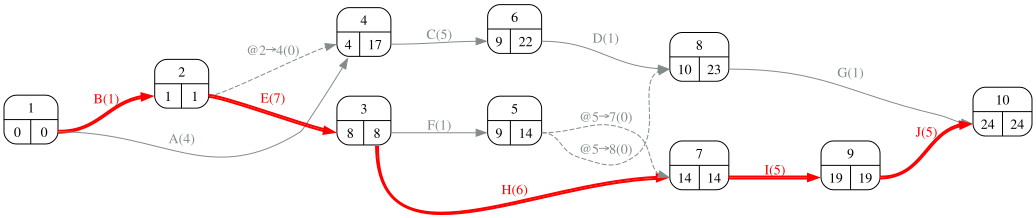

In [7]:
#| fig-cap: "Grafo PERT con tiempos y camino crítico"
#| label: fig-pert
proyecto.pert(durations=datos_proyecto['duration'], ranksep=1)

In [8]:
#| tbl-cap: "Calendario y holguras"
#| label: tbl-calendario
calendario = proyecto.calendar(datos_proyecto['duration'])
calendario

,inicio_mas_temprano,inicio_mas_tardio,fin_mas_temprano,fin_mas_tardio,H_libre,H_independiente,H_total,duracion
activity,,,,,,,,
A,0,13,4,17,0,0,13,4
B,0,0,1,1,0,0,0,1
C,4,17,9,22,0,0,13,5
D,9,22,10,23,0,0,13,1
E,1,1,8,8,0,0,0,7
F,8,13,9,14,0,0,5,1
G,10,23,11,24,13,0,13,1
H,8,8,14,14,0,0,0,6
I,14,14,19,19,0,0,0,5


## Apartado 2

In [9]:
display(Markdown(pregunta_2))

2. D y G son consecutivas y tienen la misma holgura total. El responsable de D pide retrasarla 13 semanas y el de G también. ¿Pueden concederse las dos peticiones sin alargar el proyecto? Razónelo antes de calcular.  

No. La holgura total de D y la de G son la *misma* holgura: la de la cadena en la que están. D tiene holgura libre cero, así que cualquier retraso suyo mueve el inicio de G y le consume holgura. Si D gasta las 13 semanas, G se queda sin ninguna; si además G se retrasa, el proyecto se alarga.

## Apartado 3

In [10]:
display(Markdown(pregunta_3))

3. Compruébelo: recalcule el calendario con D retrasada 13 semanas y después con las dos retrasadas.  

In [11]:
X, Y, h = 'D', 'G', 13
d1 = datos_proyecto['duration'].copy(); d1[X] += h
d2 = d1.copy(); d2[Y] += h
cal1, cal2 = proyecto.calendar(d1), proyecto.calendar(d2)
pd.DataFrame({'original': calendario.loc[[X, Y], 'H_total'], f'{X} retrasada {h}': cal1.loc[[X, Y], 'H_total'],
              'las dos retrasadas': cal2.loc[[X, Y], 'H_total']})

,original,D retrasada 13,las dos retrasadas
activity,,,
D,13,0,0
G,13,0,0


In [12]:
Markdown(f'Duración del proyecto: {duracion_proyecto} semanas en la planificación original, {proyecto.duration(d1)} con {X} retrasada '
         f'y **{proyecto.duration(d2)}** con las dos retrasadas: el segundo retraso ya no cabe en la holgura.')

Duración del proyecto: 24 semanas en la planificación original, 24 con D retrasada y **37** con las dos retrasadas: el segundo retraso ya no cabe en la holgura.

## Apartado 4

In [13]:
display(Markdown(pregunta_4))

4. ¿Qué holgura expresa cuánto puede retrasarse cada una sin quitarle margen a la otra? ¿Cómo repartiría las 13 semanas entre D y G?  

In [14]:
Markdown(f'''La holgura libre de {X} es {int(calendario.loc[X, "H_libre"])}: es lo que puede retrasarse sin mover a {Y}. La holgura independiente de {Y} es {int(calendario.loc[Y, "H_independiente"])}: lo que puede retrasarse {Y} aunque {X} acabe lo más tarde posible. Las {h} semanas son un recurso compartido de la cadena: cualquier reparto x + y ≤ {h} entre {X} y {Y} respeta el plazo; lo que no es posible es que cada una disponga de {h} por su cuenta.''')

La holgura libre de D es 0: es lo que puede retrasarse sin mover a G. La holgura independiente de G es 0: lo que puede retrasarse G aunque D acabe lo más tarde posible. Las 13 semanas son un recurso compartido de la cadena: cualquier reparto x + y ≤ 13 entre D y G respeta el plazo; lo que no es posible es que cada una disponga de 13 por su cuenta.